In [1]:
import pandas, numpy, sklearn.preprocessing, sklearn.feature_selection, sklearn.model_selection, sklearn.metrics, sklearn.linear_model, imblearn.over_sampling, matplotlib.pyplot, pickle

In [2]:
dataframe = pandas.read_csv("data/credit_card_fraud_2026.csv")
dataframe

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,19996,41.40,Healthcare,Mastercard,OTP,POS,Android Phone,False,8.82,2,...,False,False,0,17.3,2,3,False,29.6,1,0
19996,19997,47.92,Online Retail,Visa,OTP,POS,Android Phone,False,45.81,1,...,False,False,0,9.0,4,0,False,29.2,1,0
19997,19998,10.25,Restaurants,Visa,3D Secure,In-App,Tablet,False,20.67,0,...,False,False,1,1.0,19,5,False,22.9,0,0
19998,19999,31.34,Travel,Visa,3D Secure,Online,Android Phone,False,22.94,2,...,False,False,0,8.8,2,1,False,27.9,0,0


In [3]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  str    
 3   card_type                     20000 non-null  str    
 4   auth_method                   20000 non-null  str    
 5   channel                       20000 non-null  str    
 6   device_type                   20000 non-null  str    
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  account_bala

In [4]:
dataframe.describe()

,transaction_id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,132.424597,8.950827,3.191650,22.139525,46.937550,49.669400,3316.662598,0.181300,19.807735,11.533650,2.998750,37.400390,0.281250,0.016950
std,5773.647028,256.963666,8.838745,1.779544,22.120960,6.768577,18.494032,4350.720948,0.422302,12.366301,6.925335,2.004956,17.061415,0.529209,0.129087
min,1.000000,1.000000,0.010000,0.000000,0.000000,22.000000,18.000000,52.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5000.750000,26.235000,2.590000,2.000000,6.337500,42.000000,34.000000,1019.140000,0.000000,10.700000,6.000000,1.000000,25.600000,0.000000,0.000000
50%,10000.500000,57.510000,6.210000,3.000000,15.505000,47.000000,50.000000,2007.685000,0.000000,18.800000,12.000000,3.000000,35.700000,0.000000,0.000000
75%,15000.250000,131.752500,12.432500,4.000000,30.820000,51.000000,66.000000,3944.120000,0.000000,27.600000,18.000000,5.000000,47.300000,0.000000,0.000000
max,20000.000000,6872.690000,87.050000,12.000000,216.190000,74.000000,81.000000,127125.860000,3.000000,74.400000,23.000000,6.000000,100.000000,4.000000,1.000000


In [5]:
dataframe = dataframe.drop(["transaction_id"], axis=1)
dataframe

,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,22.35,...,False,False,0,0.1,18,3,False,42.3,0,0
1,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,35.28,...,False,False,0,25.8,12,4,False,28.3,0,0
2,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,9.82,...,False,True,0,42.3,5,0,False,24.7,1,0
3,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,19.72,...,False,False,0,28.9,22,6,False,56.2,1,0
4,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,17.68,...,False,False,0,3.9,2,4,False,32.7,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,41.40,Healthcare,Mastercard,OTP,POS,Android Phone,False,8.82,2,18.13,...,False,False,0,17.3,2,3,False,29.6,1,0
19996,47.92,Online Retail,Visa,OTP,POS,Android Phone,False,45.81,1,8.97,...,False,False,0,9.0,4,0,False,29.2,1,0
19997,10.25,Restaurants,Visa,3D Secure,In-App,Tablet,False,20.67,0,48.67,...,False,False,1,1.0,19,5,False,22.9,0,0
19998,31.34,Travel,Visa,3D Secure,Online,Android Phone,False,22.94,2,19.05,...,False,False,0,8.8,2,1,False,27.9,0,0


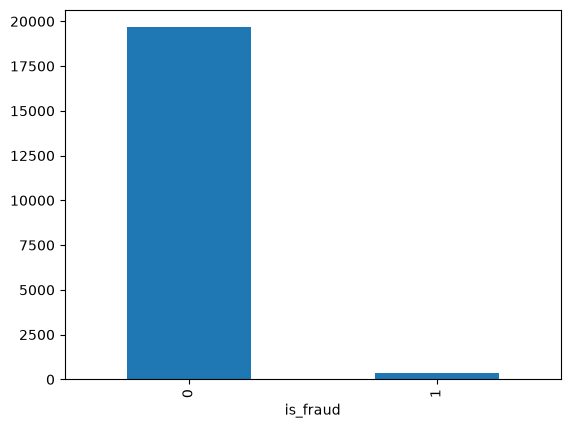

In [6]:
dataframe[dataframe.columns[-1]].value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [7]:
scaler = sklearn.preprocessing.StandardScaler()
scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [8]:
merchant_category_encoder = sklearn.preprocessing.LabelEncoder()
card_type_encoder = sklearn.preprocessing.LabelEncoder()
auth_method_encoder = sklearn.preprocessing.LabelEncoder()
channel_encoder = sklearn.preprocessing.LabelEncoder()
device_type_encoder = sklearn.preprocessing.LabelEncoder()

In [9]:
boolean_encoder = sklearn.preprocessing.OrdinalEncoder(categories=[[False, True]], unknown_value=numpy.nan, handle_unknown="use_encoded_value")
boolean_encoder

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute.","[[False, True]]"
,"handle_unknown handle_unknown: {'error', 'use_encoded_value'}, default='error'When set to 'error' an error will be raised in case an unknowncategorical feature is present during transform. When set to'use_encoded_value', the encoded value of unknown categories will beset to the value given for the parameter `unknown_value`. In:meth:`inverse_transform`, an unknown category will be denoted as None... versionadded:: 0.24",'use_encoded_value'
,"unknown_value unknown_value: int or np.nan, default=NoneWhen the parameter handle_unknown is set to 'use_encoded_value', thisparameter is required and will set the encoded value of unknowncategories. It has to be distinct from the values used to encode any ofthe categories in `fit`. If set to np.nan, the `dtype` parameter mustbe a float dtype... versionadded:: 0.24",nan
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"encoded_missing_value encoded_missing_value: int or np.nan, default=np.nanEncoded value of missing categories. If set to `np.nan`, then the `dtype`parameter must be a float dtype... versionadded:: 1.1",nan
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.3 Read more in the :ref:`User Guide <encoder_infrequent_categories>`.",None
,"max_categories max_categories: int, default=NoneSpecifies an upper limit to the number of output categories for each inputfeature when considering infrequent categories. If there are infrequentcategories, `max_categories` includes the category representing theinfrequent categories along with the frequent categories. If `None`,there is no limit to the number of output features.`max_categories` do **not** take into account missing or unknowncategories. Setting `unknown_value` or `encoded_missing_value` to aninteger will increase the number of unique integer codes by one each.This can result in up to `max_categories + 2` integer codes... versionadded:: 1.3 Read more in the :ref:`User Guide <encoder_infrequent_categories>`.",None


In [10]:
ros = imblearn.over_sampling.RandomOverSampler(sampling_strategy="minority", random_state=42)
ros

,sampling_strategy,'minority'
,random_state,42
,shrinkage,None


In [11]:
feature_selector = sklearn.feature_selection.SelectKBest(k=20, score_func=sklearn.feature_selection.chi2)
feature_selector

,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function chi...0024B9FCF01A0>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",20


In [12]:
feature_scaler = sklearn.preprocessing.MinMaxScaler(clip=True)
feature_scaler

,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",True
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True


In [13]:
X = dataframe[dataframe.columns[0:-1]]
Y = dataframe[dataframe.columns[-1]]

In [14]:
X_train, X_test, Y_train, Y_test = sklearn.model_selection.train_test_split(X, Y, stratify=Y, test_size=0.3, random_state=42)

In [15]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 14000 entries, 5440 to 8319
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   amount_usd                    14000 non-null  float64
 1   merchant_category             14000 non-null  str    
 2   card_type                     14000 non-null  str    
 3   auth_method                   14000 non-null  str    
 4   channel                       14000 non-null  str    
 5   device_type                   14000 non-null  str    
 6   is_foreign_transaction        14000 non-null  bool   
 7   hours_since_last_txn          14000 non-null  float64
 8   txn_count_last_24h            14000 non-null  int64  
 9   distance_from_home_km         14000 non-null  float64
 10  card_age_months               14000 non-null  int64  
 11  customer_age                  14000 non-null  int64  
 12  account_balance_usd           14000 non-null  float64
 13  is_new_merchant

In [16]:
X_train["merchant_category"] = merchant_category_encoder.fit_transform(X_train["merchant_category"])
X_train["card_type"] = card_type_encoder.fit_transform(X_train["card_type"])
X_train["auth_method"] = auth_method_encoder.fit_transform(X_train["auth_method"])
X_train["channel"] = channel_encoder.fit_transform(X_train["channel"])
X_train["device_type"] = device_type_encoder.fit_transform(X_train["device_type"])
X_test["merchant_category"] = merchant_category_encoder.transform(X_test["merchant_category"])
X_test["card_type"] = card_type_encoder.transform(X_test["card_type"])
X_test["auth_method"] = auth_method_encoder.transform(X_test["auth_method"])
X_test["channel"] = channel_encoder.transform(X_test["channel"])
X_test["device_type"] = device_type_encoder.transform(X_test["device_type"])

In [17]:
for i in range(len(X_train.columns)):
    if X_train[X_train.columns[i]].dtype == "bool":
        X_train[X_train.columns[i]] = boolean_encoder.fit_transform(X_train[[X_train.columns[i]]])
        X_test[X_test.columns[i]] = boolean_encoder.transform(X_test[[X_test.columns[i]]])

In [18]:
X_value = X_train
X_value

,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,...,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes
5440,104.86,8,0,2,3,3,0.0,10.67,1,26.79,...,0.0,0.0,0.0,0,8.7,11,1,0.0,20.2,0
10570,64.35,8,2,3,2,1,0.0,1.84,6,27.67,...,0.0,0.0,0.0,0,33.5,22,3,0.0,32.1,1
7784,191.73,7,4,4,4,2,0.0,9.56,2,11.29,...,0.0,0.0,0.0,0,22.5,7,4,0.0,49.8,1
11121,28.29,7,4,0,1,1,0.0,21.65,4,6.50,...,0.0,0.0,0.0,0,15.8,1,3,0.0,42.9,0
2104,194.99,5,4,4,2,5,0.0,2.57,4,7.33,...,0.0,0.0,0.0,0,16.4,5,6,0.0,28.3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3842,22.30,3,2,1,3,0,0.0,18.48,3,6.36,...,0.0,0.0,0.0,0,7.3,11,1,0.0,43.1,1
11112,12.27,9,0,2,2,7,0.0,0.70,1,18.58,...,0.0,0.0,0.0,0,22.8,23,6,0.0,23.9,0
2353,42.47,7,0,4,2,5,0.0,12.77,3,2.16,...,0.0,0.0,0.0,0,13.9,10,4,0.0,38.5,1
182,96.23,0,0,1,0,1,0.0,27.23,5,5.99,...,0.0,0.0,0.0,1,29.9,20,2,0.0,61.0,0


In [19]:
X_value = pandas.DataFrame(feature_scaler.fit_transform(X_value), columns=X_value.columns, index=X_value.index)
X_value

,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,...,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes
5440,0.015114,0.727273,0.00,0.50,0.75,0.428571,0.0,0.122472,0.090909,0.123919,...,0.0,0.0,0.0,0.000000,0.117568,0.478261,0.166667,0.0,0.202,0.00
10570,0.009219,0.727273,0.50,0.75,0.50,0.142857,0.0,0.021025,0.545455,0.127989,...,0.0,0.0,0.0,0.000000,0.452703,0.956522,0.500000,0.0,0.321,0.25
7784,0.027756,0.636364,1.00,1.00,1.00,0.285714,0.0,0.109720,0.181818,0.052223,...,0.0,0.0,0.0,0.000000,0.304054,0.304348,0.666667,0.0,0.498,0.25
11121,0.003971,0.636364,1.00,0.00,0.25,0.142857,0.0,0.248621,0.363636,0.030066,...,0.0,0.0,0.0,0.000000,0.213514,0.043478,0.500000,0.0,0.429,0.00
2104,0.028230,0.454545,1.00,1.00,0.50,0.714286,0.0,0.029412,0.363636,0.033905,...,0.0,0.0,0.0,0.000000,0.221622,0.217391,1.000000,0.0,0.283,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3842,0.003100,0.272727,0.50,0.25,0.75,0.000000,0.0,0.212201,0.272727,0.029419,...,0.0,0.0,0.0,0.000000,0.098649,0.478261,0.166667,0.0,0.431,0.25
11112,0.001640,0.818182,0.00,0.50,0.50,1.000000,0.0,0.007927,0.090909,0.085943,...,0.0,0.0,0.0,0.000000,0.308108,1.000000,1.000000,0.0,0.239,0.00
2353,0.006035,0.636364,0.00,1.00,0.50,0.714286,0.0,0.146599,0.272727,0.009991,...,0.0,0.0,0.0,0.000000,0.187838,0.434783,0.666667,0.0,0.385,0.25
182,0.013858,0.000000,0.00,0.25,0.00,0.142857,0.0,0.312730,0.454545,0.027707,...,0.0,0.0,0.0,0.333333,0.404054,0.869565,0.333333,0.0,0.610,0.00


In [20]:
Selected_features = feature_selector.fit_transform(X_value, Y_train)
X_train.columns[feature_selector.get_support()]

Index(['amount_usd', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction',
       'hours_since_last_txn', 'txn_count_last_24h', 'customer_age',
       'is_new_merchant', 'used_vpn', 'ip_country_mismatch',
       'billing_shipping_mismatch', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'is_ai_generated_scam_attempt',
       'merchant_risk_score', 'prior_disputes'],
      dtype='str')

In [21]:
X_train = X_train[X_train.columns[feature_selector.get_support()]]
X_test = X_test[X_test.columns[feature_selector.get_support()]]

In [22]:
X_train = pandas.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pandas.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

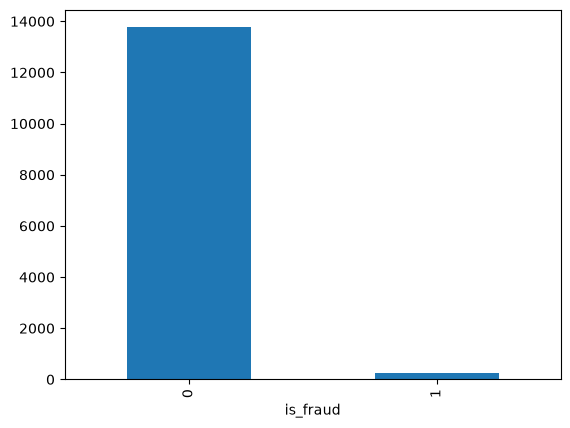

In [23]:
Y_train.value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [24]:
X_train, Y_train = ros.fit_resample(X_train, Y_train)

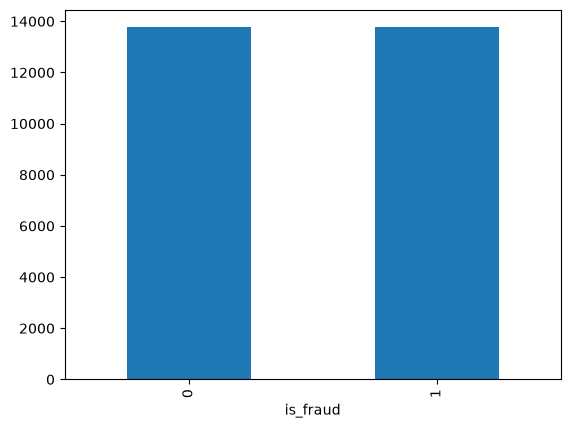

In [25]:
Y_train.value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [26]:
model = sklearn.linear_model.LogisticRegression(class_weight="balanced", l1_ratio=1.0, C=1.0, solver="liblinear", random_state=42)
model

,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1.0
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the 

In [27]:
model.fit(X_train, Y_train)

,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1.0
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the 

In [28]:
sklearn.metrics.accuracy_score(Y_test, model.predict(X_test))

0.8655

In [29]:
print(sklearn.metrics.classification_report(Y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      0.86      0.93      5898
           1       0.10      0.90      0.19       102

    accuracy                           0.87      6000
   macro avg       0.55      0.88      0.56      6000
weighted avg       0.98      0.87      0.91      6000



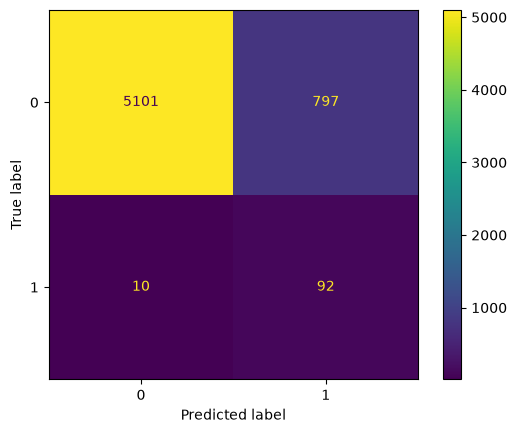

In [30]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y_test, model.predict(X_test))).plot()
matplotlib.pyplot.show()

In [31]:
sklearn.metrics.accuracy_score(Y_train, model.predict(X_train))

0.8607861658068735

In [32]:
print(sklearn.metrics.classification_report(Y_train, model.predict(X_train)))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86     13763
           1       0.86      0.86      0.86     13763

    accuracy                           0.86     27526
   macro avg       0.86      0.86      0.86     27526
weighted avg       0.86      0.86      0.86     27526



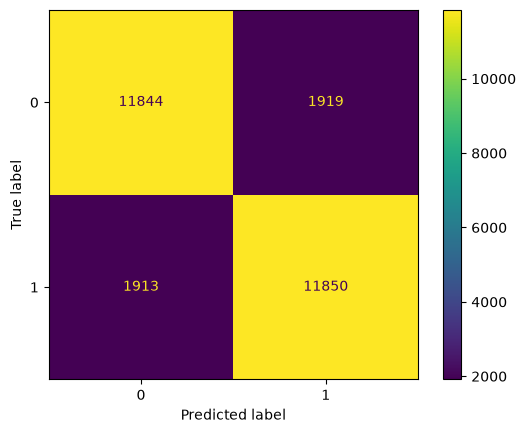

In [33]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y_train, model.predict(X_train))).plot()
matplotlib.pyplot.show()

In [34]:
X["merchant_category"] = merchant_category_encoder.fit_transform(X["merchant_category"])
X["card_type"] = card_type_encoder.fit_transform(X["card_type"])
X["auth_method"] = auth_method_encoder.fit_transform(X["auth_method"])
X["channel"] = channel_encoder.fit_transform(X["channel"])
X["device_type"] = device_type_encoder.fit_transform(X["device_type"])

In [35]:
for i in range(len(X.columns)):
    if X[X.columns[i]].dtype == "bool":
        X[X.columns[i]] = boolean_encoder.fit_transform(X[[X.columns[i]]])

In [36]:
X = X[X.columns[feature_selector.get_support()]]
X

,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,customer_age,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes
0,42.86,8,4,3,3,1,0.0,13.54,2,25,0.0,0.0,0.0,0.0,0,0.1,18,0.0,42.3,0
1,4.75,7,2,0,3,1,0.0,0.71,2,33,1.0,0.0,0.0,0.0,0,25.8,12,0.0,28.3,0
2,77.18,5,2,0,3,2,0.0,0.35,5,59,0.0,1.0,0.0,1.0,0,42.3,5,0.0,24.7,1
3,1.69,9,4,2,4,1,0.0,3.42,6,28,1.0,0.0,0.0,0.0,0,28.9,22,0.0,56.2,1
4,261.68,10,4,0,2,7,0.0,2.43,2,36,0.0,0.0,0.0,0.0,0,3.9,2,0.0,32.7,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,41.40,6,2,3,4,1,0.0,8.82,2,20,0.0,0.0,0.0,0.0,0,17.3,2,0.0,29.6,1
19996,47.92,7,4,3,4,1,0.0,45.81,1,74,0.0,0.0,0.0,0.0,0,9.0,4,0.0,29.2,1
19997,10.25,8,4,0,2,5,0.0,20.67,0,65,0.0,0.0,0.0,0.0,1,1.0,19,0.0,22.9,0
19998,31.34,10,4,0,3,1,0.0,22.94,2,45,0.0,0.0,0.0,0.0,0,8.8,2,0.0,27.9,0


In [37]:
X = pandas.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X

,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,customer_age,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes
0,-0.348558,0.707837,0.991838,0.688933,0.363384,-1.069329,-0.257095,0.519224,-0.669654,-1.333945,-0.546613,-0.310534,-0.248816,-0.213641,-0.429324,-1.593704,0.933747,-0.138233,0.287182,-0.531467
1,-0.496871,0.382589,-0.496124,-1.273560,0.363384,-1.069329,-0.257095,-0.932376,-0.669654,-0.901362,1.829448,-0.310534,-0.248816,-0.213641,-0.429324,0.484576,0.067341,-0.138233,-0.533403,-0.531467
2,-0.214995,-0.267907,-0.496124,-1.273560,0.363384,-0.662237,-0.257095,-0.973107,1.016212,0.504532,-0.546613,3.220263,-0.248816,4.680759,-0.429324,1.818881,-0.943465,-0.138233,-0.744411,1.358192
3,-0.508780,1.033085,0.991838,0.034769,1.174872,-1.069329,-0.257095,-0.625764,1.578168,-1.171726,1.829448,-0.310534,-0.248816,-0.213641,-0.429324,0.735264,1.511351,-0.138233,1.101906,1.358192
4,0.503023,1.358334,0.991838,-1.273560,-0.448103,1.373223,-0.257095,-0.737773,-0.669654,-0.739143,-0.546613,-0.310534,-0.248816,-0.213641,-0.429324,-1.286410,-1.376668,-0.138233,-0.275505,-0.531467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,-0.354240,0.057341,-0.496124,0.688933,1.174872,-1.069329,-0.257095,-0.014802,-0.669654,-1.604309,-0.546613,-0.310534,-0.248816,-0.213641,-0.429324,-0.202793,-1.376668,-0.138233,-0.457206,1.358192
19996,-0.328866,0.382589,0.991838,0.688933,1.174872,-1.069329,-0.257095,4.170286,-1.231610,1.315625,-0.546613,-0.310534,-0.248816,-0.213641,-0.429324,-0.873989,-1.087866,-0.138233,-0.480652,1.358192
19997,-0.475467,0.707837,0.991838,-1.273560,-0.448103,0.559039,-0.257095,1.325920,-1.793566,0.828969,-0.546613,-0.310534,-0.248816,-0.213641,1.938707,-1.520924,1.078148,-0.138233,-0.849915,-0.531467
19998,-0.393391,1.358334,0.991838,-1.273560,0.363384,-1.069329,-0.257095,1.582750,-0.669654,-0.252488,-0.546613,-0.310534,-0.248816,-0.213641,-0.429324,-0.890162,-1.376668,-0.138233,-0.556849,-0.531467


In [38]:
X, Y = ros.fit_resample(X, Y)

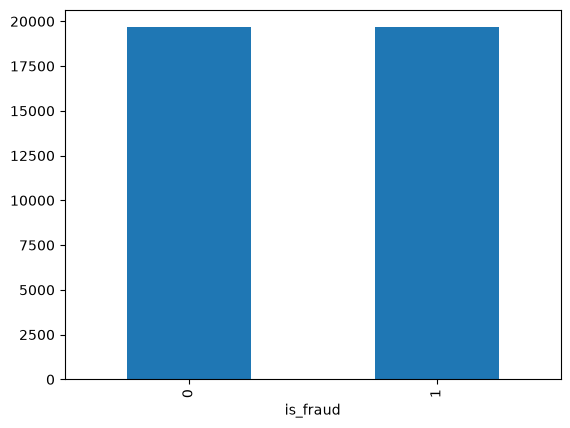

In [39]:
Y.value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [40]:
model.fit(X, Y)

,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1.0
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the 

In [41]:
sklearn.metrics.accuracy_score(Y, model.predict(X))

0.8665123849244698

In [42]:
print(sklearn.metrics.classification_report(Y, model.predict(X)))

              precision    recall  f1-score   support

           0       0.87      0.86      0.87     19661
           1       0.87      0.87      0.87     19661

    accuracy                           0.87     39322
   macro avg       0.87      0.87      0.87     39322
weighted avg       0.87      0.87      0.87     39322



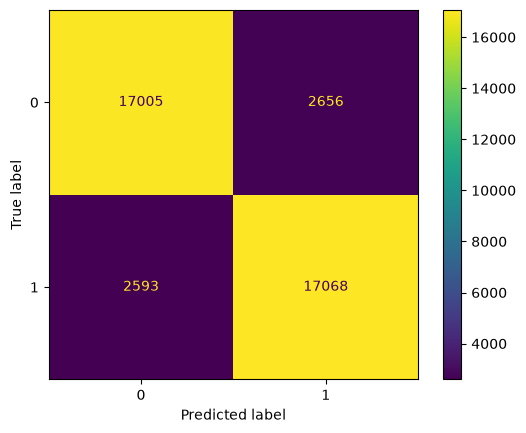

In [43]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y, model.predict(X))).plot()
matplotlib.pyplot.show()

In [44]:
with open("models/fraud_detection_model.pickle", "wb+") as file:
    pickle.dump((scaler, feature_scaler, feature_selector, boolean_encoder, merchant_category_encoder, card_type_encoder, auth_method_encoder, channel_encoder, device_type_encoder, model), file)